# BIOINF 580: Lab 3.5
### Date: Nov. 9, 2026
### GSI: Morgen Henry

---
## What is this lab?

Lab 3 introduced a set of models. This lab is a **second pass**: first a short recap of what each model is and what its settings do, then hands-on practice on a **new dataset** where you run the whole workflow yourself, check your own work, and practice writing about results.

> **Important:** the data here is a practice dataset. Its results will **not** carry over to any other dataset, so do not memorize which model "wins". What carries over is the **workflow**, the **debugging habits**, and the **way of explaining a result**.

### What you will practice
- Recapping what an SVM, an MLP, and a GMM actually are, and which settings control them.
- Exploring a dataset and **predicting** which model should work before you fit anything.
- Running a clean experiment: one split, scaling without leakage, a sweep over one setting, a plot per setting, and a results table.
- Telling apart **a model that is wrong for the data**, **a setting that is badly chosen**, and **a model that never really trained**.
- Checking AI-generated code (for example from U-M GPT) before trusting it.
- Writing a short discussion that is specific, evidence-based, and explains *why*.

### Time plan (about 25 minutes)
| Step | Minutes |
|:--|:--:|
| Skim the recap (Section 1) | 3 |
| Explore the data and predict (Section 2) | 3 |
| Worked example, linear SVM (Section 3) | 4 |
| Try It Yourself A: polynomial SVM (degree) | 4 |
| Try It Yourself B: RBF SVM | 3 |
| Try It Yourself C: MLP, then diagnose | 4 |
| AI lesson: spot the bugs and run the checks (Section 5) | 3 |
| Exit ticket | 1 |

Everything after the exit ticket is **optional extension material** for after class. Work quickly: the goal is the workflow, not perfect write-ups. Short bullet answers are fine today.

### The pattern we will use
For each skill: **I do** (worked example), **you do** (Try It Yourself), **we check** (what to verify and why).

---
# 0. Setup

1. Select the **`bioinf580`** kernel (top right).
2. Run the next cell to check your packages. If something is missing, the cell prints the right install command. (The import name is `sklearn`, but the conda package is **`scikit-learn`**.)


In [1]:
# Check that all required packages are installed and report their versions
required_packages = {"pandas": "pandas", "numpy": "numpy", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing = []

print("Checking your Python environment...\n")
for pkg, conda_name in required_packages.items():
    try:
        module = __import__(pkg)
        print(f"[OK] {pkg} (version {getattr(module, '__version__', 'unknown')}) is installed.")
    except ImportError:
        print(f"[X] {pkg} is NOT installed.")
        missing.append(conda_name)

if missing:
    print("\nWARNING: Missing packages detected:", ", ".join(missing))
    print("Please open a terminal and run:")
    print("  conda activate bioinf580")
    print("  conda install " + " ".join(missing))
    print("\nThen restart the kernel and reselect bioinf580.")
else:
    print("\nAll required packages are installed and ready to use!")

Checking your Python environment...

[OK] pandas (version 2.3.3) is installed.
[OK] numpy (version 1.26.4) is installed.
[OK] sklearn (version 1.7.2) is installed.
[OK] matplotlib (version 3.10.6) is installed.

All required packages are installed and ready to use!


---
# 1. Recap: what are these models?

Every model below answers a version of the same question: given measurements (`x1`, `x2`, ...), what can we say about each sample? Most of today's models are **supervised classifiers**: they see labels (`y`) during training and learn to predict them on new data. One (the GMM) is **unsupervised**: it never sees labels.

### Support Vector Machine (SVM)
- **Idea:** find the boundary that separates the two classes with the **widest margin**, the empty "street" between them. The training points that sit on the edge of the street are the **support vectors**; only they define the boundary.
- **Soft margin and `C`:** real data overlaps, so some points must be allowed inside the margin or on the wrong side. `C` sets the price of such mistakes. **Small `C`** tolerates mistakes and gives a wide, smooth boundary. **Large `C`** punishes mistakes and gives a narrow margin that bends to fit the training points (risking overfitting).
- **The kernel trick:** a linear SVM can only draw a straight line (a flat hyperplane in more dimensions). A **kernel** lets the SVM behave as if the data had been mapped into a richer space, so it can draw curved boundaries in the original space without ever computing that mapping.
  - **Linear:** a straight boundary.
  - **Polynomial:** combines features into products and powers. `degree` sets the highest power (more bends); `coef0` sets how much lower-order terms are mixed in with the higher-order ones.
  - **RBF (Gaussian):** similarity falls off with distance. `gamma` sets how quickly: **small `gamma`** means each point influences a wide neighborhood (smooth boundary); **large `gamma`** means very local influence (wiggly boundary that can encircle single points).
- **Output:** a signed distance to the boundary (`decision_function`). The sign gives the predicted class; the magnitude is how confident the model is.

### Multilayer Perceptron (MLP, a small neural network)
- **Idea:** stack layers of simple units. Each unit takes a weighted sum of its inputs and passes it through a nonlinear **activation function**. Stacking layers lets the network build curved, complex boundaries out of simple pieces.
- **Activation functions:** `logistic` (sigmoid) squashes values into 0 to 1; `tanh` squashes into -1 to 1; `relu` outputs 0 for negative inputs and the input itself for positive ones. They differ in how well gradients flow during training, which affects how fast (or whether) the network learns. In scikit-learn the `activation` setting applies to the **hidden** layers; the output layer is chosen automatically.
- **Training:** weights start random and are adjusted step by step to reduce a **loss** (how wrong the predictions are). Training stops when the loss stops improving enough, or at `max_iter`.
- **Watch for:** a network can stop early with a loss no better than "always predict the majority class". It reports that it converged, but it learned nothing. Always look at the **loss curve** and the number of iterations.
- **Output:** a probability for each class (`predict_proba`), which is also what you use to compute AUROC.

### Gaussian Mixture Model (GMM)
- **Idea:** assume the data were generated by a mixture of several bell-shaped (Gaussian) clusters. Fit the cluster centers, shapes, and weights, usually with the **EM algorithm**, which alternates between (E) giving each point a soft membership in each cluster and (M) re-estimating the clusters from those memberships.
- **Unsupervised:** it never sees `y`. You choose the number of clusters (`n_components`); tools such as BIC can help, but the right number depends on the data.
- **Comparing clusters with labels:** cluster numbers are arbitrary ("cluster 0" need not mean class 0; this is **label switching**). To compare with true labels, use a permutation-invariant score such as the **adjusted Rand index (ARI)**, or first map each cluster to its majority class.
- **Related methods:** see k-means (its hard-assignment cousin) and Gaussian Naive Bayes (its supervised cousin) below.

### Gaussian Naive Bayes (GNB)
- **Idea:** a **supervised** classifier built on Bayes' rule. For each class it fits one bell curve per feature, then classifies a new point by which class makes that point more probable (weighted by how common the class is). "Naive" means it assumes features are independent within a class.
- **Boundary:** because each class has its own spread, the boundary is usually a smooth curve (quadratic), not a straight line.
- **Strengths and limits:** very fast and works with little data, but its assumptions (bell-shaped, independent features) can fail badly, for example when the class shapes are not blobs.
- **Output:** class probabilities (`predict_proba`).

### k-means
- **Idea:** an **unsupervised** method that splits the data into `k` groups. Start with `k` centers, assign every point to its nearest center, move each center to the average of its points, and repeat until nothing changes.
- **Limits:** it assumes round, similarly sized clusters, gives each point exactly one cluster (a **hard** assignment), and you must choose `k`. Different random starts can give different answers, so `k-means++` initialization and several restarts (`n_init`) are standard.
- **Compared with a GMM:** a GMM is the "soft assignment, flexible cluster shapes" generalization.

### Evaluating a classifier: the confusion matrix
Every metric today comes from four counts, formed by comparing predicted labels with true labels:

| | Predicted positive | Predicted negative |
|:--|:--:|:--:|
| **Actually positive** | TP (hits) | FN (misses) |
| **Actually negative** | FP (false alarms) | TN (correct rejections) |

(Different books put actual and predicted on different axes. Always check which way a table is oriented; scikit-learn's `confusion_matrix` has **rows = actual**.)

- **Precision** = TP / (TP + FP): of the samples called positive, how many really are?
- **Sensitivity (recall)** = TP / (TP + FN): of the real positives, how many did we find?
- **Specificity** = TN / (TN + FP): of the real negatives, how many did we correctly leave alone?
- **F1** = the harmonic mean of precision and recall; low if either is low.
- **AUROC**: how well the **scores** rank positives above negatives, across every possible threshold (0.5 = random, 1.0 = perfect).
- **Why accuracy alone can mislead:** if only 22% of samples are positive, predicting "negative" for everyone is already 78% accurate and finds nobody.

### Putting it together: how do you choose?
| If the data look like... | A reasonable first guess |
|:--|:--|
| Two classes separated by a straight line | Linear SVM (simple, hard to beat) |
| Classes separated by a smooth curve | RBF SVM, or polynomial SVM of a suitable degree |
| Complex, high-dimensional patterns and plenty of data | MLP |
| Roughly blob-shaped classes, little data | Gaussian Naive Bayes |
| No labels, or you want to discover structure | GMM or k-means |

Always confirm with plots and held-out data; a guess is only a starting hypothesis.

---
## Quick recap: the settings and the metrics

Skim this table. You will use every row today.

| Model | Knob(s) you will turn | What the knob does (one line) |
|:------|:----------------------|:------------------------------|
| **Linear SVM** | `C` | Small `C`: wide, forgiving margin. Large `C`: strict, tries to classify every training point. |
| **Polynomial SVM** | `degree`, `coef0` (with `C`, `gamma` fixed) | `degree`: how many bends the boundary can have. `coef0`: mixes lower-order and higher-order terms. |
| **RBF SVM** | `gamma` | Small: each point's influence reaches far (smooth boundary). Large: very local (wiggly boundary). |
| **MLP** | `activation` (`logistic`, `tanh`, `relu`) | The nonlinearity in the hidden layers. |
| **GMM** | `n_components` | Number of Gaussian clusters. It never sees the labels. |

### The two metrics, and where each one gets its input

| Metric | Needs | In scikit-learn | Question it answers |
|:-------|:------|:----------------|:--------------------|
| **AUROC** | a continuous **score** | `roc_auc_score(y_true, model.decision_function(X))` (or `predict_proba(X)[:, 1]` if there is no `decision_function`) | How well does the model **rank** positives above negatives, across all thresholds? |
| **F1** | hard **labels** | `f1_score(y_true, model.predict(X))` | At the one threshold the model actually uses, how well does it balance precision and recall? |

> **Remember:** AUROC takes scores, F1 takes labels. Feeding `model.predict(X)` into `roc_auc_score` is one of the most common mistakes, and it silently gives a wrong answer. We will practice catching it.

---
# 2. A new dataset: explore before you model

**The story.** Imagine two standardized blood biomarkers, `x1` and `x2`, measured on 900 patients. The label `y = 1` marks patients who **responded** to a treatment. Responders are the **minority** (about 22%).

First, generate the data and save it as a CSV, so you can load it the same way you would load any data file you are handed. Run the cell once.

In [2]:
# Generate the practice dataset and save it to CSV (run once).
# You do NOT need to understand how it was generated; treat the CSV as if it were given to you.
import numpy as np
import pandas as pd

rng = np.random.default_rng(580)
def blob(center, n):
    return rng.normal(loc=center, scale=1.0, size=(n, 2))

X_gen = np.vstack([blob((-2, -2), 350), blob((2, 2), 350),      # class 0 (two groups)
                   blob((-2, 2), 100),  blob((2, -2), 100)])    # class 1 (two groups)
y_gen = np.r_[np.zeros(700), np.ones(200)].astype(int)

order = rng.permutation(len(y_gen))                              # shuffle the rows
pd.DataFrame({"x1": X_gen[order, 0], "x2": X_gen[order, 1], "y": y_gen[order]}) \
  .to_csv("biomarker_practice.csv", index=False)
print("Saved biomarker_practice.csv")

Saved biomarker_practice.csv


### Worked example: load and inspect
Notice the habits: verify the **shape** with an `assert`, look at the first rows, and check the **class balance**.

In [3]:
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv("biomarker_practice.csv")

# Verify its shape (900 rows, 3 columns: x1, x2, y)
assert df.shape == (900, 3), f"Unexpected shape: {df.shape}"

# First few rows to confirm the column names
display(df.head())

# Class balance (the minority class matters a lot for F1)
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True).round(3))

,x1,x2,y
0,-1.391241,-2.505583,0
1,-1.373971,2.221589,1
2,-1.935520,3.014700,1
3,3.104501,-2.329715,1
4,2.419003,2.519177,0


y
0    700
1    200
Name: count, dtype: int64
y
0    0.778
1    0.222
Name: proportion, dtype: float64


### Worked example: plot the data
Every plot you submit should have a **descriptive title, labeled axes, and a legend**. Here is a plot that meets that bar.

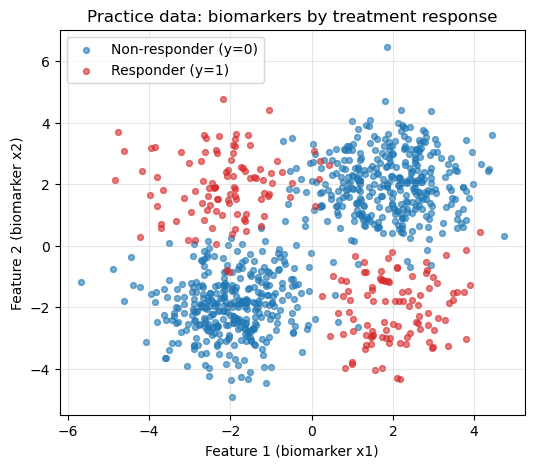

In [4]:
# Scatter plot of the two classes with different colors
fig, ax = plt.subplots(figsize=(6, 5))
for label, name, color in [(0, "Non-responder (y=0)", "tab:blue"), (1, "Responder (y=1)", "tab:red")]:
    subset = df[df["y"] == label]
    ax.scatter(subset["x1"], subset["x2"], s=18, alpha=0.6, color=color, label=name)

ax.set_title("Practice data: biomarkers by treatment response")
ax.set_xlabel("Feature 1 (biomarker x1)")
ax.set_ylabel("Feature 2 (biomarker x2)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

### Try It Yourself: explore first (write before you model!)
Look at the plot and answer in the markdown cell below, in **complete sentences**:

1. Are the two classes **linearly separable**? Could you draw one straight line that splits them? Explain what you see.
2. Are there **overlapping regions** or clear margins?
3. **Predict** which of these will do best, and which will do worst: Naive Bayes, linear SVM, polynomial SVM, RBF SVM, MLP. Justify your prediction.

**Commit to a prediction now.** The rest of the lab will show whether you were right. Being wrong and finding out why is the most useful outcome.

**Your answers:**

*double-click to edit*

---
# 3. The pipeline: split, scale, fit, evaluate

Every supervised experiment in this lab starts the same way: **one** stratified 80/20 split, then standardize using **training** statistics only. Do it once here and reuse it all lab.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[["x1", "x2"]].values
y = df["y"].values

# One train/test split: 80/20, fixed random_state, stratified on y
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize: FIT on the training set only, then TRANSFORM both sets
scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate  train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

Train: (720, 2) | Test: (180, 2)
Positive rate  train: 0.222 | test: 0.222


### Two helper functions
1. **`plot_decision_boundary(model, X, y, title, ax=None)`**: shades the model's predicted regions and overlays the points. It is defined in the next cell; you just call it.
2. **`evaluate(model, X, y)`**: returns the **AUROC** (from a score) and **F1** (from labels). It uses `decision_function` when the model has one and falls back to `predict_proba` otherwise, which is also how you score an MLP.

In [6]:
from sklearn.metrics import roc_auc_score, f1_score

def plot_decision_boundary(model, X, y, title, ax=None):
    """Shaded decision regions plus the (standardized) points."""
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap="coolwarm", alpha=0.25)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=25, alpha=0.7)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Feature 1 (standardized)")
    ax.set_ylabel("Feature 2 (standardized)")
    if show:
        plt.tight_layout(); plt.show()

def get_scores(model, X):
    """Continuous scores for AUROC: decision_function if available, else P(class 1)."""
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]

def evaluate(model, X, y):
    """Return (AUROC, F1) for a fitted model on the given data."""
    auroc = roc_auc_score(y, get_scores(model, X))    # AUROC from SCORES
    f1 = f1_score(y, model.predict(X))                # F1 from LABELS
    return auroc, f1

### Worked example (I do): Linear SVM, sweeping `C`
Read this code **line by line**. It has the structure you will copy for every other model: loop over the parameter, train, plot on the **test set** into one subplot per value, record metrics, then build a **results table**.

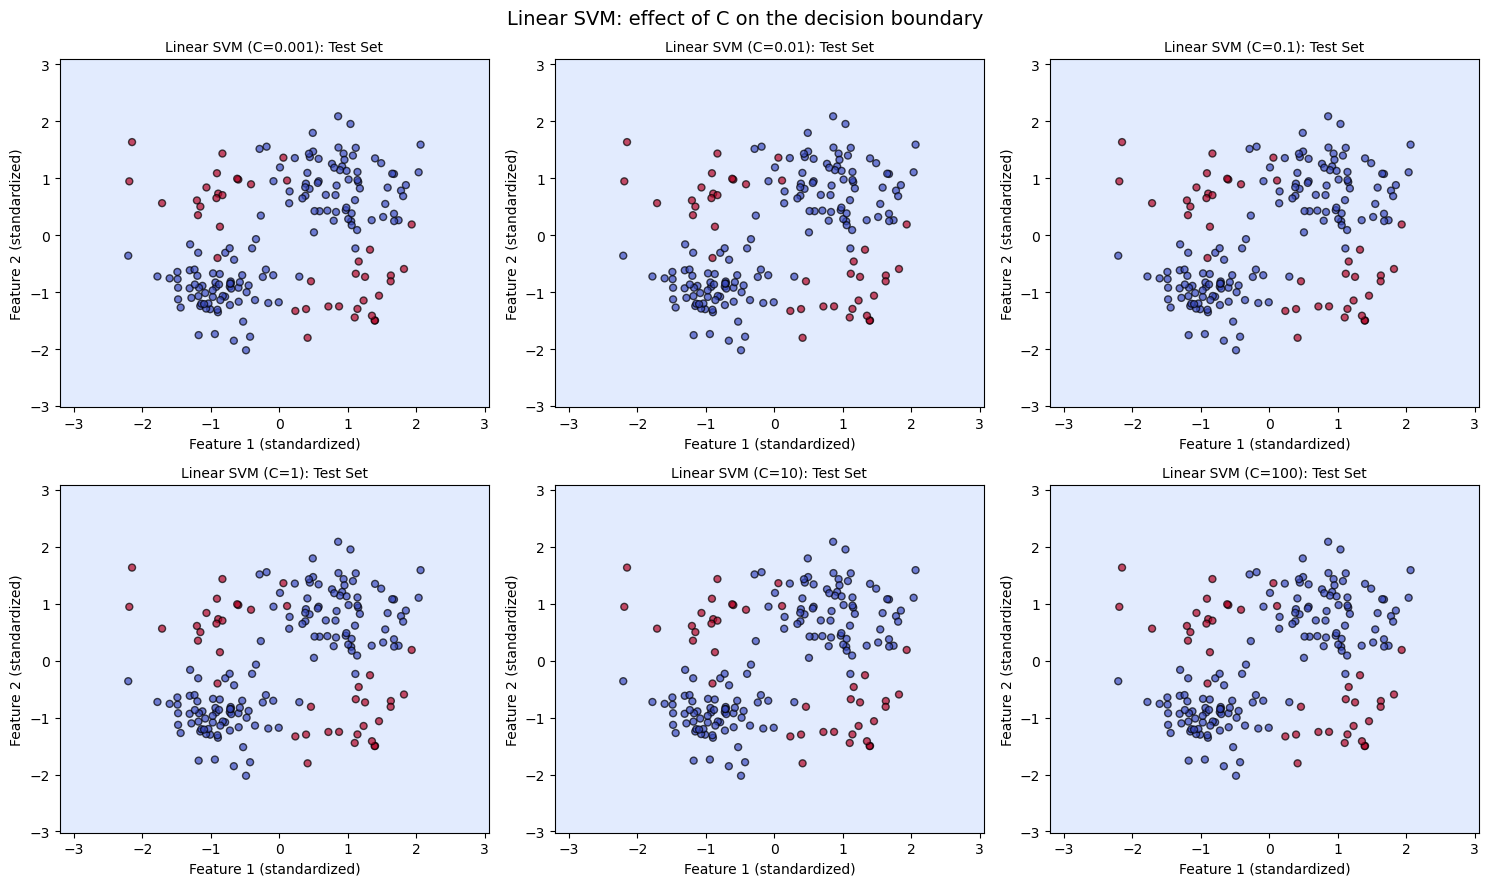

,C,AUROC,F1
0,0.001,0.501,0.0
1,0.010,0.541,0.0
2,0.100,0.454,0.0
3,1.000,0.447,0.0
4,10.000,0.449,0.0
5,100.000,0.457,0.0


In [7]:
from sklearn.svm import SVC

C_values = [0.001, 0.01, 0.1, 1, 10, 100]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
rows = []
for ax, C in zip(axes.ravel(), C_values):
    svm_linear = SVC(kernel="linear", C=C)                  # linear SVM with this C
    svm_linear.fit(X_train, y_train)                        # train on the standardized TRAIN set

    plot_decision_boundary(model=svm_linear, X=X_test, y=y_test,
                           title=f"Linear SVM (C={C}): Test Set", ax=ax)   # plot on the standardized TEST set

    auroc, f1 = evaluate(svm_linear, X_test, y_test)        # metrics on the TEST set
    rows.append({"C": C, "AUROC": auroc, "F1": f1})

plt.suptitle("Linear SVM: effect of C on the decision boundary", fontsize=14)
plt.tight_layout()
plt.show()

results_linear = pd.DataFrame(rows)                         # results table, same order as C_values
display(results_linear.round(3))

### What happened? Reading the evidence
Look at the six panels and the table.

- Every panel is shaded as **one single region**: the model assigns the whole plane to the majority class (non-responders), so no useful boundary appears at all, whatever `C` is.
- AUROC stays near **0.5** (a coin flip) and F1 is about **0** for every `C`, because the model never predicts a responder.

**Lesson:** `C` controls how strict the model is *within its family*. A linear model cannot represent this pattern (a straight line cannot isolate responders that sit in opposite corners), so no value of `C` fixes it. If you saw this in your own work you would not say "`C` is too small"; you would say "the **model family** is wrong for this data". That is also what your exploration (linearly separable or not?) should have predicted.

> **Careful:** do not expect any *other* dataset to behave like this. Your job is to read **your** plots and **your** table and explain **them**.

### Example of a strong discussion paragraph (study its structure)
Good discussions follow **Claim, Evidence, Reason**:

> **Claim.** Changing `C` did not meaningfully change the linear SVM here, and the model underfit at every setting.
> **Evidence.** In all six panels the entire plane is shaded as the majority class, so no responders are ever predicted, and the test AUROC stays near 0.5 with F1 equal to 0 for every `C` from 0.001 to 100.
> **Reason.** The two classes are arranged so that no single line can separate them, so a linear kernel is the wrong model family regardless of regularization. Adjusting `C` only changes how a straight line is tilted or how wide its margin is, which cannot add the shape the data needs.

Notice what it does **not** do: it does not just list numbers, and it does not just say "the model underfit". Each sentence points to something visible in a plot or table, and the last sentence **explains why**.

---
# 4. Try It Yourself (you do)

For each task, copy the **structure of the worked example above**: loop, train, plot into `ax`, evaluate with `evaluate(...)`, build a table. Then write a short discussion (Claim, Evidence, Reason; one or two sentences each).

## Try It Yourself A: Polynomial SVM
Fix `C = 1`, `gamma = "scale"`.

- **Round 1 (required):** `coef0 = 0`, `degree` in `[2, 3, 4, 5]`.
- **Round 2 (optional, if time):** `degree = 3`, `coef0` in `[0, 2, 5, 8, 10]`.

Produce a panel of test-set decision boundaries and a results table for Round 1.

**Questions (answer in the markdown cell):**
- (a) Which degrees work and which fail in Round 1? Look at the pattern, not just the biggest number.
- (b) *(optional)* What does `coef0` do in Round 2? Compare `coef0 = 0` with the others.
- (c) Why might an **odd** degree with `coef0 = 0` fail on this data? *(Hint below.)*

In [8]:
# YOUR CODE HERE (Try It Yourself A, Round 1: degree)

In [9]:
# YOUR CODE HERE (Try It Yourself A, Round 2: coef0, OPTIONAL)

**Your answers (a)-(c):**

*double-click to edit*

<details>
<summary><b>Hint for (c)</b></summary>

Look at where the two groups of each class sit. Class 0 has groups at roughly (-2, -2) and (2, 2). Those two points are **negatives of each other**. A homogeneous odd-degree polynomial kernel (`coef0 = 0`) produces a decision function that flips sign when you flip the input, so it struggles to give the *same* label to a point and its mirror image. Adding `coef0 > 0` breaks that symmetry.
</details>

## Try It Yourself B: RBF SVM
Fix `C = 1` and vary `gamma` in `[0.001, 0.01, 0.1, 1, 10]`. One panel of test-set boundaries, one table.

**Questions:**
- (a) Which `gamma` values look like **underfitting** (too smooth) and which look like **overfitting** (too wiggly)? Point to the panels.
- (b) Look at the table for the smallest `gamma` values. You should see something odd: a **high AUROC but an F1 near zero**. Write down your explanation before running the next cell.

In [10]:
# YOUR CODE HERE (Try It Yourself B)

**Your answers (a)-(b):**

*double-click to edit*

## Try It Yourself C: MLP activations
Train `MLPClassifier(hidden_layer_sizes=(32, 32), max_iter=1000, random_state=42)` with `activation` in `['logistic', 'tanh', 'relu']`. One panel and one table. Remember: the MLP has **no `decision_function`**, so `evaluate` will use `predict_proba`.

**Questions:**
- (a) Compare the three boundaries. Are any smoother or more segmented?
- (b) Does any activation look like it **did not learn at all**? What does its boundary look like and what do its metrics say?

In [11]:
# YOUR CODE HERE (Try It Yourself C)

**Your answers (a)-(b):**

*double-click to edit*

### Did it actually learn? Diagnose before you explain
If one activation failed, do **not** just write "it underfit". Find out what happened. Run the diagnostic below: it checks how many iterations ran, whether the loss ever went down, and compares it with a **baseline**: the loss of a model that ignores the features and just predicts the class prior.

Baseline loss (predict the class prior only): 0.530

logistic  iterations run =   34 (max 1000) | final training loss = 0.530
tanh      iterations run =  236 (max 1000) | final training loss = 0.077
relu      iterations run =  154 (max 1000) | final training loss = 0.074


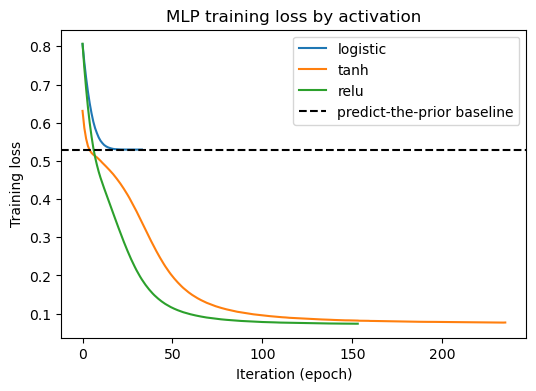

In [12]:
import warnings
from sklearn.neural_network import MLPClassifier

p = y_train.mean()
prior_loss = -(p * np.log(p) + (1 - p) * np.log(1 - p))     # loss of a model that only knows the class balance
print(f"Baseline loss (predict the class prior only): {prior_loss:.3f}\n")

fig, ax = plt.subplots(figsize=(6, 4))
for act in ["logistic", "tanh", "relu"]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                       # mute convergence chatter, we inspect it ourselves
        mlp = MLPClassifier(hidden_layer_sizes=(32, 32), activation=act,
                            max_iter=1000, random_state=42).fit(X_train, y_train)
    print(f"{act:9s} iterations run = {mlp.n_iter_:4d} (max 1000) | final training loss = {mlp.loss_:.3f}")
    ax.plot(mlp.loss_curve_, label=act)

ax.axhline(prior_loss, color="k", linestyle="--", label="predict-the-prior baseline")
ax.set_title("MLP training loss by activation")
ax.set_xlabel("Iteration (epoch)")
ax.set_ylabel("Training loss")
ax.legend()
plt.show()

**Reading it:** if one curve stops after only a few dozen iterations, sitting right on the **baseline**, the network "converged" to a useless solution: it learned the class balance and nothing else. It stopped because the loss stopped improving by more than a small tolerance, **not** because it was finished. This connects to the vanishing-gradient note about sigmoid from Lab 3: a plateau where learning is very slow. Always check the **number of iterations** and the **loss curve**, not just the final accuracy.

You can often escape the plateau by making the stopping rule more patient. Run this to see:

In [13]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    mlp_patient = MLPClassifier(hidden_layer_sizes=(32, 32), activation="logistic", max_iter=3000,
                                tol=1e-7, n_iter_no_change=200, random_state=42).fit(X_train, y_train)
auroc, f1 = evaluate(mlp_patient, X_test, y_test)
print(f"Sigmoid MLP, more patient stopping rule: iterations = {mlp_patient.n_iter_}, AUROC = {auroc:.3f}, F1 = {f1:.3f}")

Sigmoid MLP, more patient stopping rule: iterations = 3000, AUROC = 0.984, F1 = 0.886


**Why this matters:** if one of *your* activations behaves strangely, diagnose it (iterations, loss curve) before you write the explanation, and say in your report what you checked. Whether a given model misbehaves depends on the data, so always check.

---
# 5. AI lesson: debugging code you did not write

AI assistants such as **U-M GPT** are good at producing code that **looks** right and **runs**. They are much less reliable at getting every *methodological* detail right. A careful experiment protocol has many such details (split, scaling, which scores feed which metric, which set to plot), and a single wrong one can quietly change every number you report.

> **Policy note:** check the syllabus and each assignment's instructions for what AI use is allowed on graded work, and keep a record of any tool you use so you can cite it. Whatever the policy, the habit below is what makes any code, yours or an assistant's, trustworthy.

## 5.1 Spot the bugs
Below is a function an assistant might write for *"polynomial SVM sweep over degree 2 to 5, with boundaries, AUROC and F1"*. It **runs without errors**. Read it carefully first and list what you think is wrong, **then** run it.

There are **five** methodological problems. Compare each against the pipeline in Section 3.

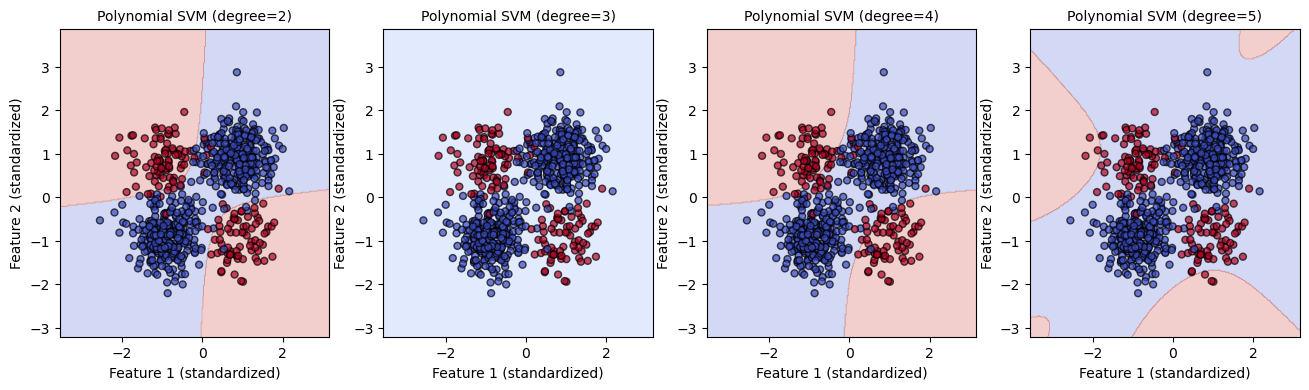

,degree,AUROC,F1
0,2,0.920,0.927
1,3,0.500,0.000
2,4,0.867,0.861
3,5,0.526,0.071


In [14]:
# WARNING: INTENTIONALLY FLAWED example of AI-generated code. Do not reuse!
def flawed_ai_pipeline(df):
    X = df[["x1", "x2"]].values
    y = df["y"].values
    X_scaled = StandardScaler().fit_transform(X)
    X_tr, X_te, y_tr, y_te = train_test_split(X_scaled, y, test_size=0.2)

    rows, models = [], []
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, deg in zip(axes, [2, 3, 4, 5]):
        m = SVC(kernel="poly", degree=deg).fit(X_tr, y_tr)
        auroc = roc_auc_score(y_te, m.predict(X_te))
        f1 = f1_score(y_tr, m.predict(X_tr))
        plot_decision_boundary(m, X_tr, y_tr, f"Polynomial SVM (degree={deg})", ax=ax)
        rows.append({"degree": deg, "AUROC": auroc, "F1": f1})
        models.append(m)
    plt.show()
    return pd.DataFrame(rows), models, (X_tr, X_te, y_tr, y_te)

bad_table, bad_models, bad_split = flawed_ai_pipeline(df)
display(bad_table.round(3))

<details>
<summary><b>Click to reveal the five problems (try first!)</b></summary>

1. **Data leakage in scaling.** `StandardScaler().fit_transform(X)` is applied to **all** the data **before** splitting, so the test set influenced the mean and standard deviation. The scaler must be **fit on the training set only**.
2. **Split not reproducible or stratified.** No `random_state=42` and no `stratify=y`, which the protocol requires. With a rare positive class, the test set can end up with a different class balance.
3. **AUROC from hard labels.** `roc_auc_score(y_te, m.predict(X_te))` uses 0/1 predictions instead of a continuous score. It must use `decision_function`.
4. **F1 computed on the training set.** `f1_score(y_tr, ...)` reports training performance. The protocol says evaluate on the **test set**.
5. **Boundaries plotted on the training set.** The protocol says to plot on the **test set** (`X_te`, `y_te`).
</details>

## 5.2 Verify with code: do not trust, check
Some bugs show up in the output, but many do not. The helper below turns the protocol into **automatic checks**. It recomputes the numbers independently and flags mismatches. Read it: this is the same kind of independent check you would write for your own code.

In [15]:
def check_split(X_tr, X_te, y_tr, y_te):
    """Check the split/scaling part of the protocol."""
    print("--- Split and scaling checks ---")
    ok_size = abs(len(X_te) / (len(X_tr) + len(X_te)) - 0.2) < 0.01
    print(f"[{'OK' if ok_size else 'X'}] About 80/20 split ({len(X_tr)} train / {len(X_te)} test)")
    gap = abs(np.mean(y_tr) - np.mean(y_te))
    print(f"[{'OK' if gap < 0.005 else 'CHECK'}] Positive rate train {np.mean(y_tr):.3f} vs. test {np.mean(y_te):.3f} (stratified splits match closely)")
    scaled_on_train = np.allclose(X_tr.mean(axis=0), 0, atol=1e-8) and np.allclose(X_tr.std(axis=0), 1, atol=1e-8)
    print(f"[{'OK' if scaled_on_train else 'X'}] Training features have mean 0 and std 1 exactly "
          f"(means = {X_tr.mean(axis=0).round(4)}); if not, the scaler was probably fit on more than the training set")

def check_results(table, models, X_te, y_te, param="degree"):
    """Recompute AUROC and F1 on the TEST set and compare with the reported table."""
    print("--- Metric checks (recomputed on the test set) ---")
    for value, rep_auroc, rep_f1, m in zip(table[param], table["AUROC"], table["F1"], models):
        auroc_true, f1_true = evaluate(m, X_te, y_te)
        good = abs(rep_auroc - auroc_true) < 1e-6 and abs(rep_f1 - f1_true) < 1e-6
        print(f"[{'OK' if good else 'X'}] {param}={value}: reported AUROC {rep_auroc:.3f}, F1 {rep_f1:.3f} | "
              f"recomputed AUROC {auroc_true:.3f}, F1 {f1_true:.3f}")

# Run the checks on the flawed function's output
check_split(*bad_split)
print()
check_results(bad_table, bad_models, bad_split[1], bad_split[3])

--- Split and scaling checks ---
[OK] About 80/20 split (720 train / 180 test)
[CHECK] Positive rate train 0.225 vs. test 0.211 (stratified splits match closely)
[X] Training features have mean 0 and std 1 exactly (means = [-0.0233  0.0042]); if not, the scaler was probably fit on more than the training set

--- Metric checks (recomputed on the test set) ---
[X] degree=2: reported AUROC 0.920, F1 0.927 | recomputed AUROC 0.991, F1 0.880
[X] degree=3: reported AUROC 0.500, F1 0.000 | recomputed AUROC 0.302, F1 0.000
[X] degree=4: reported AUROC 0.867, F1 0.861 | recomputed AUROC 0.989, F1 0.817
[X] degree=5: reported AUROC 0.526, F1 0.071 | recomputed AUROC 0.475, F1 0.100


Notice what the checks caught and what they could not. The scaling bug and the wrong metrics are flagged automatically. The **plot-on-the-wrong-set** and **missing `random_state`** problems still need a human reading the code against the protocol. **Automatic checks and careful reading are complementary.**

---
# Optional extensions (after class)

The rest of this notebook is for practice on your own time. It is not needed to finish the lab in class.

- **Test your explanation of high AUROC with low F1** (confusion matrix and precision-recall)
- **Try It Yourself D:** Gaussian mixture model versus the true labels, and more clusters than classes
- **Ask U-M GPT and verify** (5.3)
- **Writing a strong discussion** and a **self-check list** (Sections 6 and 7)

### Investigating "high AUROC, low F1"
Run this cell to test your explanation. It fits the smallest-`gamma` model and looks at what it actually **predicts**.

In [16]:
from sklearn.metrics import confusion_matrix, precision_recall_curve

svm_small_gamma = SVC(kernel="rbf", C=1, gamma=0.001).fit(X_train, y_train)
scores = svm_small_gamma.decision_function(X_test)
pred = svm_small_gamma.predict(X_test)

print("Number of test points predicted positive:", int(pred.sum()), "out of", len(pred))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, pred))
print(f"AUROC = {roc_auc_score(y_test, scores):.3f} | F1 at the default threshold (0) = {f1_score(y_test, pred):.3f}")

# What if we moved the decision threshold? Find the best F1 over all possible thresholds.
precision, recall, thresholds = precision_recall_curve(y_test, scores)
f1_all = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
best = np.argmax(f1_all[:-1])
print(f"Best achievable F1 by moving the threshold = {f1_all[best]:.3f} at threshold {thresholds[best]:.3f}")

Number of test points predicted positive: 0 out of 180
Confusion matrix (rows = actual, columns = predicted):
[[140   0]
 [ 40   0]]
AUROC = 0.981 | F1 at the default threshold (0) = 0.000
Best achievable F1 by moving the threshold = 0.911 at threshold -0.999


**Reading it:** AUROC only asks whether positives get **higher scores** than negatives (ranking). F1 depends on where the **threshold** is. With a very small `gamma` and a rare positive class, the scores rank the points well, but none of them cross the default threshold of 0, so the model **predicts almost no positives**. Ranking was fine; the *threshold* was the problem. This "good AUROC but mediocre F1" combination is common whenever the positive class is rare.

## Try It Yourself D: GMM vs. the true labels
Use **only** `x1` and `x2` (all 900 rows, **no labels** when fitting).

1. Fit `GaussianMixture(n_components=2, random_state=42)` on the features.
2. Predict the cluster for every sample.
3. Make a **two-panel figure**: left = colored by GMM cluster, right = colored by true label.
4. Compute the **Adjusted Rand Index (ARI)** between clusters and labels with `adjusted_rand_score`.

**Questions:**
- (a) Do the clusters line up with the labels? Where do they disagree?
- (b) **Label-switching trap:** GMM's cluster "0" is just a name. If the colors in your two panels look swapped, is that an error? How does ARI avoid the problem?
- (c) GMM is unsupervised. Given where the classes sit, why might 2 clusters not match 2 classes?

In [17]:
# YOUR CODE HERE (Try It Yourself D)

**Your answers (a)-(c):**

*double-click to edit*

### Extension: more clusters than classes
Sometimes the right move is **more clusters than classes**, then map each cluster to a class. Run this cell, which uses 4 components and assigns each cluster the **majority true label** of its members.

In [18]:
from collections import Counter
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score

X_all = df[["x1", "x2"]].values
y_all = df["y"].values

gmm4 = GaussianMixture(n_components=4, n_init=5, random_state=42).fit(X_all)
clusters4 = gmm4.predict(X_all)

# Map each cluster to the majority class among its members
mapping = {c: Counter(y_all[clusters4 == c]).most_common(1)[0][0] for c in range(4)}
mapped = np.array([mapping[c] for c in clusters4])

print("Cluster -> class mapping:", mapping, "| cluster sizes:", np.bincount(clusters4))
print(f"After mapping: accuracy = {accuracy_score(y_all, mapped):.3f}, F1 = {f1_score(y_all, mapped):.3f}")

Cluster -> class mapping: {0: 1, 1: 0, 2: 1, 3: 0} | cluster sizes: [104 345 105 346]
After mapping: accuracy = 0.963, F1 = 0.919


**Reading it:** the labels were used here **only to name clusters afterward**, never to fit the model, and the mapping is something you decide after the fact. Note also that "accuracy for 2 components" can look decent just because the majority class is large (a model that calls everyone class 0 would be about 78% accurate here). That is why we also look at ARI and F1.

## 5.3 Your turn: ask U-M GPT, then verify
1. Open **umgpt.umich.edu** and sign in (uniqname, UMICH password, MFA). Use **only this practice data**, never real or sensitive data.
2. Write a **specific prompt**: context + task + constraints + output format. Example:

```text
CONTEXT:  I have standardized arrays X_train, X_test (n x 2) and labels y_train, y_test
          for a binary classification problem. A function plot_decision_boundary(model, X, y, title, ax)
          already exists. I use scikit-learn.
TASK:     Train an RBF SVM for gamma in [0.001, 0.01, 0.1, 1, 10] with C=1. For each gamma:
          plot the decision boundary on the TEST set in one subplot, and record AUROC and F1 on the TEST set.
CONSTRAINTS: AUROC must use decision_function, F1 must use predict(). Do not refit the scaler.
          Do not re-split the data; use the variables above.
OUTPUT:   One code cell with comments, ending with a pandas DataFrame named table_ai and a list named models_ai.
```
3. **Read before you run.** Compare against the protocol line by line. Look up any function you do not recognize in the scikit-learn documentation (U-M GPT is not connected to it).
4. Paste the code below, run it, then run the verification cell after it.

In [19]:
# YOUR CODE HERE: paste and edit the assistant's code.
# It should produce a DataFrame named table_ai (with columns gamma, AUROC, F1) and a list models_ai.

In [20]:
# Verify your assistant-generated results with the same independent checks
if "table_ai" in globals() and "models_ai" in globals():
    check_results(table_ai, models_ai, X_test, y_test, param="gamma")
else:
    print("Define table_ai and models_ai in the cell above first.")

Define table_ai and models_ai in the cell above first.


### Log what you did (a record like this also helps with your **References**)

| Item | Your notes |
|:-----|:-----------|
| The prompt I used (final version) | |
| What the assistant got wrong or I had to change | |
| Documentation pages I checked | |
| My independent checks and what they showed | |
| Something I still do not understand | |

---
# 6. Writing a strong discussion

In a written report, much of the value is in the **discussion** text. Strong answers are **specific**, **evidence-based**, and **explain why**.

### The Claim, Evidence, Reason pattern
1. **Claim:** one sentence that directly answers the question asked.
2. **Evidence:** what you *see* in your plots and table (name the panel, the parameter value, or the number).
3. **Reason:** *why*, in terms of what the parameter or model actually does (margin, curvature, locality, threshold, saturation).

### Weak vs. strong

| Weak | Strong |
|:-----|:-------|
| "Larger gamma is better." | "As gamma rises from 0.1 to 10 the boundary breaks into small islands around individual points, and AUROC drops, which indicates overfitting because each point's influence has become very local." |
| "AUROC and F1 are different." | "AUROC stays high while F1 falls to 0 at the smallest gamma because the scores still rank positives above negatives, but none cross the default threshold, so almost no positives are predicted." |
| "The MLP underfit." | "The sigmoid MLP stopped after 34 iterations with a loss equal to the class-prior baseline, so it learned only the class balance; a more patient stopping rule fixed it." |

### Questions to ask yourself before you submit each discussion
- Did I answer **every** question in the prompt, in **complete sentences**?
- Does every claim point to something **visible** in my own figures or table?
- Did I say **why**, not just what?
- Did I avoid assuming my dataset behaves like a different one (including this practice dataset)?

---
# 7. Self-check before you submit any analysis

**Mechanics (for any model-comparison analysis)**
- [ ] One stratified 80/20 split with `random_state=42`; scaler **fit on train only**.
- [ ] AUROC from `decision_function` (or `predict_proba[:, 1]` for the MLP); F1 from `predict`.
- [ ] Boundaries plotted on the **standardized test set**, one subplot per value.
- [ ] Results table in the **same order** as the parameter values.
- [ ] Every plot has a **title, axis labels, and legend** where appropriate.
- [ ] Every code block has **comments**; unnecessary prints are **commented out**.

**Thinking**
- [ ] Before modeling: described separability and overlap, and **predicted** the best model *before* modeling.
- [ ] If a model looks broken, I **diagnosed** it (iterations, loss curve, predicted-positive counts) before explaining it.
- [ ] GMM: compared with labels using **ARI**, and I understand label switching.
- [ ] Discussions use **Claim, Evidence, Reason**.

**Submission**
- [ ] Any tools or sources I used are listed as **references**, and I followed the course AI policy.
- [ ] The notebook contains all code **and** the written discussion, and it runs top to bottom after a kernel restart.
